# NumPy 的函数群 ― 从随机数到数组操作

## 本章要学什么

除了 `ndarray` 和 ufunc 之外，NumPy 还有大量处理数组的函数，用它们就能不写循环地完成计算，程序既短又快。这一章通过例子确认其中最常用的那些函数。

- 生成随机数的函数，以及用种子固定结果的方法
- 求和、平均、方差，以及 `axis`、`keepdims`、`dtype` 的用法
- 排序，以及求最大值、最小值位置的函数
- 去掉重复值、直方图之类的统计函数
- 按条件选值的 `where()` 与 `piecewise()`
- 连接与分割数组的函数

各节都用表格把函数列出来，具体的参数等到需要时再查即可。

下面从生成随机数的函数开始看，因为随机数在后面的计算函数里也会用到。

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import helper.matplotlib
import helper.magics

## 随机数

`numpy.random` 模块里有很多与随机数有关的函数，先看最基本的几个。

| 函数名 | 功能 | 函数名 | 功能 |
|:--|:--|:--|:--|
| `rand`  | 0 到 1 之间的随机数 | `randn`  | 标准正态分布的随机数 |
| `randint`  | 指定范围内的随机整数 | `normal` | 正态分布 |
| `uniform` | 均匀分布 | `poisson` | 泊松分布 |
| `permutation` | 随机排列 | `shuffle` | 随机打乱顺序 |
| `choice` | 随机抽取样本 | `seed` | 设置随机数种子 |

* `rand()` 返回 0 到 1 之间的随机数，参数是所要生成数组的形状。
* `randn()` 返回标准正态分布的随机数，参数的含义与 `rand()` 相同。
* `randint()` 返回指定范围内的随机整数，包含起始值而不包含终止值，下面的例子按第 3 个参数给出的形状生成 0 到 9 的随机数。

In [2]:
from numpy import random as nr

np.set_printoptions(precision=2)   # 为了让输出短一些，只保留小数点后 2 位

rand_uniform = nr.rand(4, 3)            # 0〜1 的均匀随机数
rand_normal = nr.randn(4, 3)            # 標準正規分布
rand_int = nr.randint(0, 10, (4, 3))    # 0〜9 的整数

%C rand_uniform; rand_normal; rand_int

    rand_uniform            rand_normal          rand_int 
--------------------  -----------------------  -----------
[[0.4 , 0.3 , 0.03],  [[ 0.88, -0.86,  0.48],  [[1, 8, 7],
 [0.38, 0.27, 0.47],   [ 0.42,  1.49,  0.1 ],   [5, 0, 7],
 [0.68, 0.29, 0.27],   [ 0.6 , -0.33,  0.57],   [3, 2, 3],
 [0.79, 0.78, 0.61]]   [-0.8 , -1.33,  0.04]]   [8, 4, 7]]


`random` 模块里还有按指定概率分布生成随机数的函数。它们最后一个 `size` 参数是输出的形状，其余参数都是分布的参数。

* `normal()`：正态分布，前两个参数是平均值和标准差。
* `uniform()`：均匀分布，前两个参数是区间的起点和终点。
* `poisson()`：泊松分布，第一个参数是 $\lambda$，表示单位时间(或单位面积)内随机事件发生的平均次数；泊松分布是离散分布，返回的数组是整数数组。

In [3]:
rand_normal = nr.normal(100, 10, (4, 3))   # 平均 100、標準偏差 10
rand_uniform = nr.uniform(10, 20, (4, 3))  # 10〜20 的均匀随机数
rand_poisson = nr.poisson(2.0, (4, 3))     # 平均 2 次的泊松分布

%C rand_normal; rand_uniform; rand_poisson

       rand_normal                rand_uniform       rand_poisson
--------------------------  -----------------------  ------------
[[114.06,  97.51, 110.05],  [[15.63, 13.08, 17.42],  [[3, 0, 5], 
 [ 83.25,  95.38, 109.9 ],   [18.07, 12.36, 14.83],   [2, 0, 4], 
 [ 91.54,  96.58,  94.63],   [15.89, 11.92, 17.03],   [0, 1, 0], 
 [125.36, 107.6 ,  99.25]]   [14.61, 15.6 , 11.04]]   [1, 3, 4]] 


`permutation()` 返回一个随机排列：参数是整数 `n` 时，返回把 $[0, n)$ 的整数打乱顺序的数组；参数是序列时，返回把它的元素打乱顺序的数组。

In [4]:
a = np.array([1, 10, 20, 30, 40])
print(nr.permutation(10))   # 打乱 0〜9 的顺序
print(nr.permutation(a))    # 打乱数组元素的顺序

[2 4 1 0 5 3 9 7 8 6]
[10 30 20  1 40]


`permutation()` 返回新的数组，而 `shuffle()` 直接改变作为参数传进去的那个数组本身的顺序。

In [5]:
nr.shuffle(a)   # a 自身的顺序被改变
a

array([10, 20, 40, 30,  1])

`choice()` 从指定的数组里随机取出元素，常用的参数有三个。

* `size` 是输出的形状。
* `replace` 为 `True` 时允许重复抽取，为 `False` 时不重复，默认值是 `True`。下面的例子里 `sample_dup` 可能含有相同的值，`sample_uniq` 的各个值都不相同。
* `p` 是每个元素被抽到的概率，不指定时所有元素的概率相同。下面的例子里，值越大的元素越容易被抽到。

In [6]:
a = np.arange(10, 25, dtype=float)
sample_dup = nr.choice(a, size=(4, 3))                        # 允许重复
sample_uniq = nr.choice(a, size=(4, 3), replace=False)        # 不允许重复
sample_weighted = nr.choice(a, size=(4, 3), p=a / np.sum(a))  # 值越大越容易被抽到

%C sample_dup; sample_uniq; sample_weighted

    sample_dup        sample_uniq      sample_weighted 
-----------------  -----------------  -----------------
[[10., 21., 22.],  [[22., 21., 11.],  [[22., 23., 12.],
 [14., 23., 14.],   [15., 24., 23.],   [20., 23., 19.],
 [18., 22., 13.],   [12., 19., 16.],   [16., 23., 12.],
 [20., 18., 14.]]   [13., 17., 18.]]   [15., 21., 11.]]


想再生成一次同样的随机数，就用 `seed()` 指定随机数的种子。下面的例子里，`r3` 与 `r4` 在生成之前都以 42 为种子，因此两者是同一个数组。

In [7]:
r1 = nr.randint(0, 100, 3)
r2 = nr.randint(0, 100, 3)
nr.seed(42)
r3 = nr.randint(0, 100, 3)
nr.seed(42)
r4 = nr.randint(0, 100, 3)
%C r1; r2; r3; r4

     r1            r2            r3            r4     
------------  ------------  ------------  ------------
[93, 48, 49]  [48, 58, 86]  [51, 92, 14]  [51, 92, 14]


## 求和、平均、方差

| 函数名 | 功能 | 函数名 | 功能 |
|:--|:--|:--|:--|
|`sum`|求和|`mean`|平均|
|`average`|加权平均|`std`|标准差|
|`var`|方差|`product`|乘积|

`sum()` 返回数组各元素的总和，也可以用在列表、元组这类形似数组的序列上；对多维数组来说，它求的是所有元素的总和。这里先生成一个随机的整数数组来试。

In [8]:
np.random.seed(42)
a = np.random.randint(0, 10, size=(4, 5))
%C a; np.sum(a)

        a           np.sum(a)  
-----------------  ------------
[[6, 3, 7, 4, 6],  np.int64(96)
 [9, 2, 6, 7, 4],              
 [3, 7, 7, 2, 5],              
 [4, 1, 7, 5, 1]]              


指定 `axis` 就沿该轴求和。上面例子里数组 `a` 的第 0 轴长度是 4、第 1 轴长度是 5，因此 `axis=1` 求的是每一行那 5 个值的和，结果是长度为 4 的一维数组；`axis=0` 求的是每一列那 4 个值的和，结果是长度为 5 的一维数组。也就是说，结果的形状就是从原数组形状里去掉该轴之后的样子。这条规律对后面所有带 `axis` 参数的函数都成立。

In [9]:
%C np.sum(a, axis=1); np.sum(a, axis=0)

np.sum(a, axis=1)   np.sum(a, axis=0)  
-----------------  --------------------
[26, 28, 24, 18]   [22, 13, 27, 18, 16]


给 `axis` 传一个轴的元组，就会对指定的所有轴一起求和。下面的程序对形状为 `(2, 3, 4)` 的三维数组的第 0 轴和第 2 轴求和，所以结果的形状是 `(3,)`；由于元素全是 1，每个和都是 8。

In [10]:
np.sum(np.ones((2, 3, 4)), axis=(0, 2))

array([8., 8., 8.])

如果希望保留原来的维数，就把 `keepdims` 设为 `True`。

In [11]:
%C np.sum(a, 1, keepdims=True); np.sum(a, 0, keepdims=True)

np.sum(a, 1, keepdims=True)  np.sum(a, 0, keepdims=True)
---------------------------  ---------------------------
[[26],                       [[22, 13, 27, 18, 16]]     
 [28],                                                  
 [24],                                                  
 [18]]                                                  


`sum()` 默认按数组元素的类型来累加：元素是整数时就按 int64 累加，因此总和一旦超出该类型的范围就会溢出。

下面的程序计算数组 `a` 的每个元素在所在行总和里所占的比例，调用 `sum()` 时指定了两个参数。

* `dtype=float`：让求和用浮点数进行，从而避免整数除法。
* `keepdims=True`：把和的形状保持为 `(4, 1)`，以便与原数组广播。

In [12]:
pa = a / np.sum(a, 1, dtype=float, keepdims=True) * 100
%C 2 pa; pa.sum(1, keepdims=True)

                  pa                   pa.sum(1, keepdims=True)
-------------------------------------  ------------------------
[[23.08, 11.54, 26.92, 15.38, 23.08],  [[100.],                
 [32.14,  7.14, 21.43, 25.  , 14.29],   [100.],                
 [12.5 , 29.17, 29.17,  8.33, 20.83],   [100.],                
 [22.22,  5.56, 38.89, 27.78,  5.56]]   [100.]]                


对很大的单精度浮点数数组，累加的精度有时不够用，这种情况同样可以用 `dtype` 指定累加时使用的类型。下面的例子把全为 1.1 的单精度数组求和，并比较按单精度累加与按双精度累加的结果。

In [13]:
np.set_printoptions(precision=8)
big_float32 = np.full(1000000, 1.1, dtype=np.float32)   # 100 万个 1.1
big_float32   # 1.1 无法用二进制精确表示，所以有一点误差

array([1.1, 1.1, 1.1, ..., 1.1, 1.1, 1.1], shape=(1000000,), dtype=float32)

按单精度累加时误差会变大，而按双精度累加就接近准确值。

In [14]:
%C np.sum(big_float32); np.sum(big_float32, dtype=np.double)

   np.sum(big_float32)     np.sum(big_float32, dtype=np.double)
-------------------------  ------------------------------------
np.float32(1.1000001e+06)  np.float64(1100000.023841858)       


如果想把求和的结果写进已有的数组而不是新建一个，就像 ufunc 那样指定 `out`，不过 `out` 的形状必须与结果的形状相同。

`mean()` 返回平均值，参数与 `sum()` 相同。与 `sum()` 不同的是，它对整数数组会用双精度浮点数计算，而对其他类型则按元素类型本身计算。

In [15]:
np.mean(a, axis=1)   # 整数数组按双精度计算

array([5.2, 5.6, 4.8, 3.6])

In [16]:
%C np.mean(big_float32); np.mean(big_float32, dtype=np.double)

 np.mean(big_float32)  np.mean(big_float32, dtype=np.double)
---------------------  -------------------------------------
np.float32(1.1000001)  np.float64(1.100000023841858)        


`average()` 也能求平均。它没有 `out` 和 `dtype`，但可以给每个元素指定权重 `weights`，据此计算加权平均。例如有 3 个班级，`number` 里存各班的人数，`score` 里存各班的平均分，那么整个年级的平均分就是用人数加权之后的平均。

In [17]:
score = np.array([83, 72, 79])
number = np.array([20, 15, 30])
print(np.average(score, weights=number))

78.61538461538461


这与下面的计算完全相同。

In [18]:
print(np.sum(score * number) / np.sum(number, dtype=float))

78.61538461538461


`std()` 与 `var()` 分别返回标准差和方差，它们有 `axis`、`out`、`dtype`、`keepdims` 等参数。方差的定义有两种，其中有偏样本方差(biased sample variance)的式子如下。

$$s_n^2 = \frac{1}{n} \sum_{i=1}^n\left(y_i - \overline{y} \right)^ 2$$

无偏样本方差(unbiased sample variance)的式子则是下面这样。

$$s^2 = \frac{1}{n-1} \sum_{i=1}^n\left(y_i - \overline{y} \right)^ 2$$

两者的差别只在分母：一个有偏，除以 $n$；另一个无偏，除以 $n-1$。`ddof` 为 0 时有偏，为 1 时无偏，默认值是 0；下面的程序确认这两种方差的差别。

首先从标准差 2.0、方差 4.0 的正态分布里生成随机数，也就是把总体的方差当作 4.0，从中取出 10 个值并计算这两种方差；把这个过程用二维数组重复 10 万次，再求方差的平均值。

In [19]:
a = nr.normal(0, 2.0, (100000, 10))   # 10 万行 × 10 列，1 行是一次抽样
v1 = np.var(a, axis=1, ddof=0)         # 有偏样本方差(ddof 可以省略)
v2 = np.var(a, axis=1, ddof=1)         # 无偏样本方差
%C np.mean(v1); np.mean(v2)

         np.mean(v1)                     np.mean(v2)         
------------------------------  -----------------------------
np.float64(3.6008566906846697)  np.float64(4.000951878538522)


无偏样本方差的平均值会接近总体的方差 4.0，而有偏样本方差会比 4.0 略小。

有偏样本方差实际上是正态分布参数的最大似然估计。已知 n 个值服从正态分布时，就可以从这些值估计正态分布的参数；在估计出的参数之中，让给定数据最可能出现的那个就叫最大似然估计。

正态分布的概率密度函数如下，其中 $\mu$ 是平均值、$\sigma^2$ 是方差。

$$f(x\mid \mu,\sigma^2) = \frac{1}{\sqrt{2\pi\sigma^2}} e^{-\frac{(x-\mu)^2}{2\sigma^2}}$$

最大似然估计要找的就是让下面这个乘积最大的参数，其中 $x_i$ 是样本的值。

$$f(x_1) f(x_2) \cdots f(x_n)$$

光靠文字不容易看明白，还是用程序确认一下。

In [20]:
def normal_pdf(mean, var, x):
    """返回正态分布的概率密度。"""
    return 1 / np.sqrt(2 * np.pi * var) * np.exp(-((x - mean) ** 2) / (2 * var))


nr.seed(42)
data = nr.normal(0, 2.0, size=10)                        # ❶ 10 个正态分布随机数
mean, var = np.mean(data), np.var(data)                  # ❷ 最大似然估计的参数
var_range = np.linspace(max(var - 4, 0.1), var + 4, 100)  # ❸ 方差的候选值

p = normal_pdf(mean, var_range[:, None], data)           # ❹ 各候选值下的概率密度
p = np.prod(p, axis=1)                                   # ❺ 10 个值的乘积(似然)

`normal_pdf()` 是计算正态分布概率密度的函数：❶ 先生成 10 个服从正态分布的随机数，❷ 再计算它们最大似然估计的参数，❸ 然后以估计出的方差为中心，准备一批方差的候选值。

❹ 对每个候选方差，分别计算这 10 个值的概率密度；由于用到了广播，结果 `p` 是二维数组，第 0 轴对应 `var_range` 里的各个方差，第 1 轴对应 `data` 的各个元素。❺ 最后沿第 1 轴求概率密度的乘积，`prod()` 的用法与 `sum()` 相同，只是求的是元素之积。

下图是 `var_range` 里各个方差所对应的似然，红色竖线标出的是有偏样本方差所在的位置。

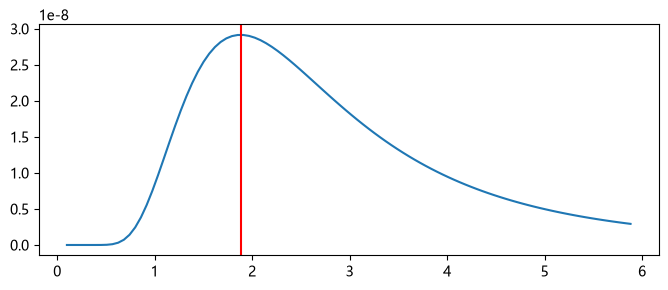

In [21]:
plt.figure(figsize=(8, 3))
plt.plot(var_range, p)
plt.axvline(var, 0, 1, c="r")
plt.show()

## 排序与大小

| 函数名 | 功能 | 函数名 | 功能 |
|:--|:--|:--|:--|
| `min`  | 最小值 | `max`  | 最大值 |
| `minimum`  | 二元最小值 | `maximum`  | 二元最大值 |
| `ptp`  | 最大值与最小值之差 | `argmin` | 最小值的下标 |
| `argmax` | 最大值的下标 | `unravel_index` | 把一维下标转换成多维下标 |
| `sort` | 排序数组 | `argsort` | 计算排序后的下标 |
| `lexsort` | 多列排序 | `partition` | 高速求出前 `k` 个 |
| `argpartition` | 前 `k` 个的下标 | `median` | 中位数 |
| `percentile` | 百分位数 | `searchsorted` | 二分查找 |

`min()` 与 `max()` 返回数组的最小值和最大值。它们有 `axis`、`out`、`keepdims` 等参数，用法与 `sum()` 几乎相同，只是 `axis` 不能传元组。`ptp()` 返回最大值与最小值之差，有 `axis` 和 `out` 两个参数。

`minimum()` 与 `maximum()` 比较两个数组同一位置上的元素，返回较小(或较大)的那一个，结果的形状是两个数组广播之后的形状。

In [22]:
a = np.array([1, 3, 5, 7])
b = np.array([2, 4, 6])
np.maximum(a[None, :], b[:, None])   # 列出所有组合中较大的那个

array([[2, 3, 5, 7],
       [4, 4, 5, 7],
       [6, 6, 6, 7]])

`argmax()` 与 `argmin()` 返回最大值和最小值所在的位置(下标)。不指定 `axis` 时，返回的是把数组展平成一维之后的下标；最大值出现多次时，返回第一个位置。

In [23]:
np.random.seed(42)
a = np.random.randint(0, 10, size=(4, 5))
max_pos = np.argmax(a)
max_pos

np.int64(5)

把 `a` 展平成一维，再取出下标 `max_pos` 处的元素看看，它应该与最大值相等。

In [24]:
%C a.ravel()[max_pos]; np.max(a)

a.ravel()[max_pos]   np.max(a) 
------------------  -----------
np.int32(9)         np.int32(9)


`unravel_index()` 把展平后数组的下标转换成多维数组的下标，第 1 个参数是展平时的下标，第 2 个参数是多维数组的形状。

In [25]:
max_index = np.unravel_index(max_pos, a.shape)
%C max_index; a[max_index]

        max_index           a[max_index]
--------------------------  ------------
(np.int64(1), np.int64(0))  np.int32(9) 


指定 `axis` 就沿该轴返回最大值的位置，下面的结果说明第 0 行的最大値在第 2 列、第 1 行的最大值在第 0 列。

In [26]:
row_argmax = np.argmax(a, axis=1)
row_argmax

array([2, 0, 1, 2])

有了这个下标，就可以把各行最大值一次取出来。

In [27]:
a[np.arange(a.shape[0]), row_argmax]

array([7, 9, 7, 7], dtype=int32)

数组的 `sort()` 方法直接对数组本身排序，而 `sort()` 函数返回新的数组、不改动原数组。两者的 `axis` 默认值都是 -1，也就是沿最后一轴排序。`sort()` 函数还可以取 `axis=None`，这时会先展平再排序。下面的例子里，`np.sort(a)` 对每一行排序，`np.sort(a, axis=0)` 对每一列排序。

In [28]:
%C np.sort(a); np.sort(a, axis=0)

    np.sort(a)     np.sort(a, axis=0)
-----------------  ------------------
[[3, 4, 6, 6, 7],  [[3, 1, 6, 2, 1], 
 [2, 4, 6, 7, 9],   [4, 2, 7, 4, 4], 
 [2, 3, 5, 7, 7],   [6, 3, 7, 5, 5], 
 [1, 1, 4, 5, 7]]   [9, 7, 7, 7, 6]] 


`argsort()` 返回排序之后的下标，`axis` 的默认值是 -1。

In [29]:
sort_axis1 = np.argsort(a)
sort_axis0 = np.argsort(a, axis=0)
%C sort_axis1; sort_axis0

    sort_axis1         sort_axis0   
-----------------  -----------------
[[1, 3, 0, 4, 2],  [[2, 3, 1, 2, 3],
 [1, 4, 2, 3, 0],   [3, 1, 0, 0, 1],
 [3, 0, 4, 1, 2],   [0, 0, 2, 3, 2],
 [1, 4, 0, 3, 2]]   [1, 2, 3, 1, 0]]


下面用 `sort_axis0` 和 `sort_axis1` 做出与 `np.sort(a)` 相同的结果。由于还需要没有排序的那些轴的下标，这里用 `ogrid` 生成第 0 轴和第 1 轴的下标。

In [30]:
axis0, axis1 = np.ogrid[: a.shape[0], : a.shape[1]]

用这些下标把排序之后的数组取出来。

In [31]:
%C a[axis0, sort_axis1]; a[sort_axis0, axis1]

a[axis0, sort_axis1]  a[sort_axis0, axis1]
--------------------  --------------------
[[3, 4, 6, 6, 7],     [[3, 1, 6, 2, 1],   
 [2, 4, 6, 7, 9],      [4, 2, 7, 4, 4],   
 [2, 3, 5, 7, 7],      [6, 3, 7, 5, 5],   
 [1, 1, 4, 5, 7]]      [9, 7, 7, 7, 6]]   


用这个办法，可以把两个互相关联的数组按同一顺序排序：先对一个数组算 `argsort()`，再用它返回的下标去索引另一个数组。排序的函数和方法都有 `kind` 参数，用来指定排序算法；对结构体数组则用 `order` 指定参与排序的字段。

`lexsort()` 类似于 Excel 里的多列排序。参数是形状为 `(k, N)` 的数组，或者 k 个长度为 `N` 的数组组成的序列，可以把它想成 Excel 里 N 行 k 列的一张表。`lexsort()` 返回排序用的下标，不过要注意最后一列才是第一关键字；下面的例子把姓名和年龄的数据按“姓名、年龄”的顺序排序。

In [32]:
names = ["zhang", "wang", "li", "wang", "zhang"]
ages = [37, 33, 32, 31, 36]
order = np.lexsort([ages, names])   # 最后一列(姓名)是第一关键字
sorted_data = np.array(list(zip(names, ages)), "O")[order]
%C order; sorted_data

     order         sorted_data  
---------------  ---------------
[2, 3, 1, 4, 0]  [['li', 32],   
                  ['wang', 31], 
                  ['wang', 33], 
                  ['zhang', 36],
                  ['zhang', 37]]


要把 N 行 k 列的数组按第 1 列排序，就用切片 `[::-1]` 把列的顺序反过来，转置之后再传给 `lexsort()`。

In [33]:
b = np.random.randint(0, 10, (5, 3))
%C b; b[np.lexsort(b[:, ::-1].T)]

     b       b[np.lexsort(b[:, ::-1].T)]
-----------  ---------------------------
[[4, 0, 9],  [[3, 8, 2],                
 [5, 8, 0],   [4, 0, 9],                
 [9, 2, 6],   [4, 2, 6],                
 [3, 8, 2],   [5, 8, 0],                
 [4, 2, 6]]   [9, 2, 6]]                


`partition()` 与 `argpartition()` 把数组分割开来，快速找出排序之后的前 k 个。它不需要整体排序，因此比先用 `sort()` 全排再取前几个要快得多。下面的例子要从 10 万个随机数里找出最小的 5 个，需要注意 `partition()` 返回的 5 个值并没有按从小到大排列，必要时再用 `sort()` 排一次。

In [34]:
r = np.random.randint(10, 1000000, 100000)
%C np.sort(r)[:5]; np.partition(r, 5)[:5]

   np.sort(r)[:5]     np.partition(r, 5)[:5]


--------------------  ----------------------
[15, 23, 25, 37, 47]  [15, 23, 25, 37, 47]  


用 `%timeit` 比较 `sort()` 与 `partition()` 的执行时间。

In [35]:
%timeit np.sort(r)[:5]
%timeit np.sort(np.partition(r, 5)[:5])

837 μs ± 238 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


120 μs ± 2.99 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


`median()` 返回中位数，也就是排序之后位于正中间的值，元素个数为偶数时取中间两个值的平均；它也可以指定 `axis` 和 `out`。

In [36]:
np.median(a, axis=1)

array([6., 6., 5., 4.])

`percentile()` 返回百分位数，也就是把值从小到大排列之后处于 $p\%$ 位置上的那个值。下面的程序对标准正态分布随机数的绝对值，计算 $68.3\%$、$95.4\%$、$99.7\%$ 三个位置，它们大致等于标准差的 1 倍、2 倍和 3 倍。

In [37]:
r = np.abs(np.random.randn(100000))
np.percentile(r, [68.3, 95.4, 99.7])

array([1.00029686, 1.99473003, 2.9614485 ])

如果数组的元素已经按从小到大排好，就可以用 `searchsorted()` 做二分查找。下面例子里的 `a` 是排好序的列表，`v` 是要查找的值组成的列表：`searchsorted()` 返回把 `v` 的每个元素插入 `a` 之后仍能保持升序的位置。当 `v` 的某个值在 `a` 里也存在时，可以用 `side` 选择返回左端还是右端。下面的例子里 16 插到 `a` 的下标 3、4、5 都能保持升序，`side` 取默认的 `"left"` 时返回 3，取 `"right"` 时返回 5。

In [38]:
a = [2, 4, 8, 16, 16, 32]
v = [1, 5, 33, 16]
%C np.searchsorted(a, v); np.searchsorted(a, v, side="right")

np.searchsorted(a, v)  np.searchsorted(a, v, side="right")
---------------------  -----------------------------------
[0, 2, 6, 3]           [0, 2, 6, 5]                       


有了 `searchsorted()`，就可以在两个数组中查找相同的元素。下面的例子有两个一维数组 `x` 和 `y`，要求出 `y` 的每个元素在 `x` 里排第几，`x` 里没有的值记为 -1。

In [39]:
x = np.array([3, 5, 7, 1, 9, 8, 6, 10])
y = np.array([2, 1, 5, 10, 100, 6])


def get_index_searchsorted(x, y):
    """返回 y 的每个元素在 x 中排第几，x 里没有的记为 -1。"""
    order = np.argsort(x)                                  # ❶ 把 x 升序排列的下标
    sorted_x = x[order]                                    # ❷ 排好序的 x
    sorted_index = np.searchsorted(sorted_x, y)            # ❸ 插入 y 的位置
    yindex = np.take(order, sorted_index, mode="clip")     # ❹ 还原成原来的 x 中的下标
    mask = x[yindex] != y                                  # ❺ 找出值不一致的
    yindex[mask] = -1
    return yindex


get_index_searchsorted(x, y)

array([-1,  3,  1,  7, -1,  6])

❶ 由于 `x` 并没有按升序排列，先用 `argsort()` 求出排序用的下标 `order`；❷ 再用这个下标把 `x` 排好序得到 `sorted_x`；❸ 然后用 `searchsorted()` 求出 `y` 的每个元素在 `sorted_x` 中的插入位置。

❹ 如果要查找的值比 `x` 的最大值还大，得到的位置就会超出范围，所以这里用 `take()`。`take(order, sorted_index)` 的含义与 `order[sorted_index]` 相同，但可以处理越界的下标；取 `mode="clip"` 时，下标会被限制在 `0` 到 `len(x)-1` 之间。

❺ 最后用 `yindex` 从 `x` 里取出元素与 `y` 比较：两者相同说明 `x` 里有这个元素，不同则说明没有。

这个办法稍显复杂，但全部计算都只用 NumPy 的数组操作完成，因此比用字典写 Python 循环要快。下面的例子用两个较大的数组比较速度；为了条件一致，用 `tolist()` 把数组先转成了列表。

In [40]:
x = np.random.permutation(1000)[:100]
y = np.random.randint(0, 1000, 2000)
xl, yl = x.tolist(), y.tolist()


def get_index_dict(x, y):
    """用字典的版本，用来做比较。"""
    idx_map = {v: i for i, v in enumerate(x)}
    return [idx_map.get(v, -1) for v in y]


yindex1 = get_index_searchsorted(x, y)
yindex2 = get_index_dict(xl, yl)
print(np.all(yindex1 == yindex2))

%timeit get_index_searchsorted(x, y)
%timeit get_index_dict(xl, yl)

True


71.7 μs ± 1.79 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


178 μs ± 4.39 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


## 统计函数

| 函数名 | 功能 | 函数名 | 功能 |
|:--|:--|:--|:--|
| `unique`  | 去掉重复元素 | `bincount`  | 统计整数数组各元素的出现次数 |
| `histogram`  | 一维直方图统计 | `digitize` | 离散化 |

`unique()` 返回数组中所有不同的值，并按从小到大排列，它有两个可选参数。

* `return_index`：为 `True` 时同时返回各值在原数组中的下标。
* `return_inverse`：为 `True` 时返回能重建原数组的下标。

先生成 10 个 0 到 7 的整数来试 `unique()`。

In [41]:
np.random.seed(42)
data = np.random.randint(0, 8, 10)
%C data; np.unique(data)

             data                np.unique(data)  
------------------------------  ------------------
[6, 3, 4, 6, 2, 7, 4, 4, 6, 1]  [1, 2, 3, 4, 6, 7]


把 `return_index` 设为 `True` 时会返回两个数组，第 2 个数组给出第 1 个数组里各个值在原数组中第一次出现的位置；下面的例子里，`first_index` 就是 `unique_values` 的每个元素在 `data` 中的位置。

In [42]:
unique_values, first_index = np.unique(data, return_index=True)
%C unique_values; first_index; data[first_index]

  unique_values        first_index      data[first_index] 
------------------  ------------------  ------------------
[1, 2, 3, 4, 6, 7]  [9, 4, 1, 2, 0, 5]  [1, 2, 3, 4, 6, 7]


把 `return_inverse` 设为 `True` 时，第 2 个数组给出的是原数组 `data` 的每个元素在 `unique_values` 中的位置。

In [43]:
unique_values, inverse = np.unique(data, return_inverse=True)
%C inverse; unique_values[inverse]

           inverse                  unique_values[inverse]    
------------------------------  ------------------------------
[4, 2, 3, 4, 1, 5, 3, 3, 4, 0]  [6, 3, 4, 6, 2, 7, 4, 4, 6, 1]


`bincount()` 统计整数数组中每个值出现的次数，数组的元素必须都不小于 0；返回数组的第 `i` 个元素就是整数 `i` 出现的次数。

In [44]:
np.bincount(data)

array([0, 1, 1, 1, 3, 0, 3, 1])

从上面的结果可以看出，`data` 里 1 出现 1 次、2 出现 1 次、3 出现 1 次、4 出现 3 次、6 出现 3 次、7 出现 1 次，而 0 和 5 没有出现。

用 `weights` 可以给每个值加上权重，`bincount(x, weights=w)` 会把 `x` 的每个整数所对应的 `w` 中的权重累加起来。

In [45]:
x = np.array([0, 1, 2, 2, 1, 1, 0])
w = np.array([0.1, 0.3, 0.2, 0.4, 0.5, 0.8, 1.2])
np.bincount(x, w)

array([1.3, 1.6, 0.6])

结果里的 1.3 是 `x` 中 0 所对应的 `w` 元素(0.1 与 1.2)之和，1.6 是 1 所对应元素(0.3、0.5、0.8)之和，0.6 则是 2 所对应元素(0.2 与 0.4)之和；想求平均值，把总和除以次数即可。

In [46]:
np.bincount(x, w) / np.bincount(x)

array([0.65      , 0.53333333, 0.3       ])

`histogram()` 计算一维数组的直方图，参数如下。

    histogram(a, bins=10, range=None, weights=None, density=False)

其中 `a` 是待统计的数据，`bins` 是区间的个数，`range` 是长度为 2 的元组、用来指定统计范围的最小值和最大值，默认值 `None` 表示由数据的范围决定。`density` 为 `False` 时返回各区间的数据个数，为 `True` 时返回各区间的概率密度，`weights` 的含义与 `bincount()` 相同。

`histogram()` 返回两个一维数组 `hist` 和 `bin_edges`：`hist` 是各区间的统计结果，`bin_edges` 的长度是 `len(hist) + 1`，相邻的两个值构成一个区间。

In [47]:
data = np.random.rand(100)
np.histogram(data, bins=5, range=(0, 1))

(array([28, 18, 17, 19, 18]), array([0. , 0.2, 0.4, 0.6, 0.8, 1. ]))

这里生成了 100 个 0 到 1 的随机数并按 5 个区间统计，结果 0 到 0.2 之间有 28 个、0.2 到 0.4 之间有 18 个。由于 `rand()` 生成的随机数在 0 到 1 之间均匀分布，区间取得越多，每个区间里的个数就越接近。

想改变区间的宽度，就把分隔位置组成的数组传给 `bins`。

In [48]:
np.histogram(data, bins=[0, 0.4, 0.8, 1.0])

(array([46, 36, 18]), array([0. , 0.4, 0.8, 1. ]))

这次 0 到 0.4 之间有 46 个，0.4 到 0.8 之间有 36 个。

指定 `weights` 则会累加落入各区间的值的权重。下面的例子统计 100 位 7 岁到 20 岁的男性的年龄和身高，数据放在 `data/height.csv` 里。

先用 `loadtxt()` 读出文件，数组 `d` 的第 0 列是年龄、第 1 列是身高，年龄从 7 岁到 20 岁，以小数形式存放。

In [49]:
d = np.loadtxt("data/height.csv", delimiter=",")
%C d.shape; np.min(d[:, 0]); np.max(d[:, 0])

d.shape   np.min(d[:, 0])  np.max(d[:, 0]) 
--------  ---------------  ----------------
(100, 2)  np.float64(7.1)  np.float64(19.9)


接着计算按年龄分组的身高总和 `sums` 以及每个年龄的人数 `cnts`，两者相除就得到每个年龄的平均身高。

In [50]:
sums = np.histogram(d[:, 0], bins=range(7, 21), weights=d[:, 1])[0]   # 按年龄分组的身高总和
cnts = np.histogram(d[:, 0], bins=range(7, 21))[0]                   # 每个年龄的人数
sums / cnts

array([125.96      , 132.06666667, 137.82857143, 143.8       ,
       148.14      , 153.44      , 162.15555556, 166.86666667,
       172.83636364, 173.3       , 175.275     , 174.19166667,
       175.075     ])

`histogram2d()` 与 `histogramdd()` 分别统计二维和 N 维的数据，其中 `histogram2d()` 会在讲图像处理的那一章用到。

## 分段函数

| 函数名 | 功能 | 函数名 | 功能 |
|:--|:--|:--|:--|
| `where`  | 向量化的条件表达式 | `select`  | 多分支条件选择 |
| `piecewise`  | 分段函数 | - | - |

三角波就是一个分段函数。它的计算式随自变量的范围而改变，所以用单个 ufunc 写不出来，NumPy 为此提供了几种计算分段函数的办法。

Python 里有按条件选值的表达式，`condition` 为 `True` 时取 `y`，否则取 `z`。

```python
x = y if condition else z
```

NumPy 的 `where()` 就是把这种表达式推广到数组上。

```python
x = where(condition, y, z)
```

其中 `condition`、`y`、`z` 都是数组，返回值是与 `condition` 形状相同的数组：`condition` 的元素为 `True` 时取 `y` 同一位置的值，为 `False` 时取 `z` 同一位置的值。

In [51]:
x = np.arange(10)
np.where(x < 5, 9 - x, x)   # x < 5 时取 9 - x，否则取 x

array([9, 8, 7, 6, 5, 5, 6, 7, 8, 9])

当 `y` 和 `z` 是单个数值、或者与 `condition` 的形状不同时，会用广播把形状对齐。

In [52]:
np.where(x > 6, 2 * x, 0)

array([ 0,  0,  0,  0,  0,  0,  0, 14, 16, 18])

有了 `where()`，三角波也能轻松写出来。

In [53]:
def triangle_wave1(x, x_fall, x_rise, height):
    """三角波，周期为 1。"""
    x = x - x.astype(np.int32)   # 周期为 1，所以只取小数部分
    return np.where(
        x >= x_fall,
        0,
        np.where(x < x_rise, x / x_rise * height, (x_fall - x) / (x_fall - x_rise) * height),
    )

三角波分成 3 个区间，所以要把 `where()` 嵌套两层使用。所有计算都在 C 语言这一层完成，因此比用 Python 循环写要快得多。

不过区间一多，`where()` 的嵌套就会变深，程序也越来越难读。这时就该改用 `select()`，调用形式如下。

```python
select(condlist, choicelist, default=0)
```

`condlist` 是长度为 `N` 的布尔数组组成的列表，`choicelist` 是长度为 `N` 的值数组组成的列表，其中每个数组的长度都是 `M`；如果列表里的元素不是数组而是单个数值，就把它当作所有元素都等于该值、长度为 `M` 的数组。

对 0 到 `M-1` 的每个下标 `i`，找出使 `condlist[j][i]` 为 `True` 的最小 `j`，并令 `out[i] = choicelist[j][i]`，这个 `out` 就是 `select()` 的返回值。用 `select()` 写三角波就是下面这样。

In [54]:
def triangle_wave2(x, x_fall, x_rise, height):
    x = x - x.astype(np.int32)
    return np.select(
        [x >= x_fall, x < x_rise, True],
        [0, x / x_rise * height, (x_fall - x) / (x_fall - x_rise) * height],
    )

三角波分成 3 个区间，所以两个列表里都有 3 个元素。由于 `condlist` 的最后一项是 `True`，当前面的条件都不成立时就会取第 3 个值；也可以用 `default` 指定条件都不成立时的值。

```python
return np.select([x >= x_fall, x < x_rise],
                 [0, x / x_rise * height],
                 default=(x_fall - x) / (x_fall - x_rise) * height)
```

不过 `where()` 和 `select()` 在调用之前都会把所有参数算出来，也就是说下面这 4 个数组都会被生成。

```python
x >= x_fall, x < x_rise, x / x_rise * height, (x_fall - x) / (x_fall - x_rise) * height
```

计算过程中还会产生好几个存放中间结果的数组，输入数组 `x` 一大，内存的分配和释放就要反复进行。

In [55]:
def triangle_wave3(x, x_fall, x_rise, height):
    x = x - x.astype(np.int32)
    return np.piecewise(
        x,
        [x >= x_fall, x < x_rise],
        [0, lambda x: x / x_rise * height, lambda x: (x_fall - x) / (x_fall - x_rise) * height],
    )

为了避开这个问题，可以使用 `piecewise()`，它的参数如下。

```python
piecewise(x, condlist, funclist)
```

`x` 是自变量的数组，`condlist` 是长度为 `M` 的布尔数组组成的列表、每个数组的长度与 `x` 相同。`funclist` 则是长度为 `M` 或 `M+1` 的函数组成的列表，每个函数接受数组并返回数组；函数的位置上也可以放数值，这时把它当作总是返回该值的函数。每个函数负责计算 `condlist` 中对应布尔数组的那一段；如果 `funclist` 的长度是 `M+1`，最后一个函数就负责计算所有条件都不成立时的值。用 `piecewise()` 写三角波就是下面这样。

In [56]:
x = np.linspace(0, 2, 10000)
y1 = triangle_wave1(x, 0.6, 0.4, 1.0)
y2 = triangle_wave2(x, 0.6, 0.4, 1.0)
y3 = triangle_wave3(x, 0.6, 0.4, 1.0)
np.all(y1 == y2), np.all(y1 == y3)

(np.True_, np.True_)

In [57]:
%timeit triangle_wave1(x, 0.6, 0.4, 1.0)
%timeit triangle_wave2(x, 0.6, 0.4, 1.0)
%timeit triangle_wave3(x, 0.6, 0.4, 1.0)

182 μs ± 7.55 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


250 μs ± 5.81 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


182 μs ± 4.64 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


`piecewise()` 只计算需要的值：上面例子里 `x / x_rise * height` 和 `(x_fall - x) / (x_fall - x_rise) * height` 都只对 `x` 中满足条件的部分计算。下面比较三个函数的结果，并用 `%timeit` 测一下执行时间。

In [58]:
a = np.arange(3)
b = np.arange(10, 13)

v = np.vstack((a, b))        # (2, 3)
h = np.hstack((a, b))        # (6,)
c = np.column_stack((a, b))  # (3, 2)
%C v; h; c

      v                    h                  c     
--------------  ------------------------  ----------
[[ 0,  1,  2],  [ 0,  1,  2, 10, 11, 12]  [[ 0, 10],
 [10, 11, 12]]                             [ 1, 11],
                                           [ 2, 12]]


## 多维数组的操作

| 函数名 | 功能 | 函数名 | 功能 |
|:--|:--|:--|:--|
| `concatenate`  | 连接多个数组 | `vstack`  | 沿第 0 轴连接数组 |
| `hstack`  | 沿第 1 轴连接数组 | `column_stack` | 按列连接多个一维数组 |
| `split, array_split`   | 把数组分割成几部分 | `transpose` | 改变轴的顺序 |
| `swapaxes` | 交换两个轴的顺序 | | |

`concatenate()` 是连接多个数组的基本函数，其余几个都是它的简化版。第 1 个参数是数组的序列，用 `axis`(默认是第 0 轴)指定沿哪个轴连接，要求参与连接的数组除该轴之外形状全都相同。

`vstack()` 沿第 0 轴连接；如果参与连接的是长度为 `N` 的一维数组，会先把形状变成 `(1, N)` 再连接。

`hstack()` 沿第 1 轴连接；如果所有数组都是一维的，就沿第 0 轴连接，结果也是一维的。

`column_stack()` 与 `hstack()` 相似，但它会把一维数组的形状变成 `(N, 1)` 再连接，需要把多个一维数组并成列时常用它。

In [59]:
np.c_[a, b, a + b]

array([[ 0, 10, 10],
       [ 1, 11, 12],
       [ 2, 12, 14]])

`c_[]` 对象同样可以按列连接数组。

In [60]:
np.set_printoptions(linewidth=25)
np.random.seed(42)
a = np.random.randint(0, 10, 12)
split_points = np.nonzero(np.diff(a) < 0)[0] + 1
%C a; split_points; np.split(a, split_points)
np.set_printoptions(linewidth=80)

           a                  split_points      np.split(a, split_points)
------------------------  --------------------  -------------------------
[6, 3, 7, 4, 6, 9, 2, 6,  [ 1,  3,  6,  9, 10]  [array([6], dtype=int32),
 7, 4, 3, 7]                                     array([3, 7],           
                                                       dtype=int32),     
                                                 array([4, 6, 9],        
                                                       dtype=int32),     
                                                 array([2, 6, 7],        
                                                       dtype=int32),     
                                                 array([4], dtype=int32),
                                                 array([3, 7],           
                                                       dtype=int32)]     


`split()` 与 `array_split()` 沿指定的轴把数组分割开，可以直接指定分割位置的下标。下面的代码把一个随机数数组按升序段切开：`diff()` 与 `nonzero()` 得到的下标是各升序段最后一个元素的位置，而分割点应当在段首，所以要加 1。

In [61]:
%C np.split(a, 6); np.array_split(a, 5)

       np.split(a, 6)               np.array_split(a, 5)     
----------------------------  -------------------------------
[array([6, 3], dtype=int32),  [array([6, 3, 7], dtype=int32),
 array([7, 4], dtype=int32),   array([4, 6, 9], dtype=int32),
 array([6, 9], dtype=int32),   array([2, 6], dtype=int32),   
 array([2, 6], dtype=int32),   array([7, 4], dtype=int32),   
 array([7, 4], dtype=int32),   array([3, 7], dtype=int32)]   
 array([3, 7], dtype=int32)]                                 


第 2 个参数是整数时表示要分成的组数：`split()` 只在能等分时才分割，而 `array_split()` 会尽量平均地分。

In [62]:
a = np.random.randint(0, 10, (2, 3, 4, 5))
print("原数组形状:", a.shape)
print("transpose:", np.transpose(a, (1, 2, 0, 3)).shape)
print("swapaxes:", np.swapaxes(a, 1, 2).shape)

原数组形状: (2, 3, 4, 5)
transpose: (3, 4, 2, 5)
swapaxes: (2, 4, 3, 5)


`transpose()` 与 `swapaxes()` 改变轴的顺序并返回原数组的视图。`transpose()` 用第 2 个参数 `axes` 指定轴的顺序，省略时把所有轴逆序排列；`swapaxes()` 则用两个整数指定要交换的轴。下面的例子里，`transpose()` 的结果形状是 `(3, 4, 2, 5)`，也就是把原形状 `(2, 3, 4, 5)` 的轴按 `(1, 2, 0, 3)` 的顺序重排；`swapaxes()` 的结果是 `(2, 4, 3, 5)`，即把中间两个轴互换。

In [63]:
from pathlib import Path
from imageio.v3 import imread

images = []
for fn in Path("data/thumbnails").glob("*.png"):
    images.append(imread(fn))

print(images[0].shape)

(90, 160, 3)


作为改变轴顺序的例子，这里把很多缩略图排成一张大图。`data/thumbnails` 里有 30 张 160×90 的 PNG 图像，要把它们排成 6 行 5 列。先用 `pathlib` 和 `imageio` 把图像读进来，做出数组的列表 `images`。

In [64]:
img = np.concatenate(images, 0)
img.shape

(2700, 160, 3)

`images` 的每个元素都是形状为 `(90, 160, 3)` 的数组，其中第 0 轴是图像高度、第 1 轴是宽度、第 2 轴是通道数；彩色图像有红、绿、蓝 3 个通道，所以第 2 轴的长度是 3。

用 `concatenate()` 把这些数组沿第 0 轴合成一个，结果是一幅宽 160、高 2700 的图像。

In [65]:
grid = img.reshape(6, 5, 90, 160, 3)
grid[0, 1].shape

(90, 160, 3)

目标是排成 6 行 5 列的缩略图，为此要把 `img` 的第 0 轴拆成 3 个轴，长度分别为 `(6, 5, 90)`。用 `reshape()` 变换形状之后，就可以用 `grid[i, j]` 取出第 i 行第 j 列的图像。

排好之后的图像是 `(540, 800, 3)`，也就是 `(6*90, 5*160, 3)`，这与形状为 `(6, 90, 5, 160, 3)` 的多维数组是同一份数据。与 `grid` 相比，需要把第 1 轴和第 2 轴互换，所以先用 `swapaxes()` 或 `transpose()` 交换轴，再用 `reshape()` 变成 `(540, 800, 3)`。

In [66]:
tiled = grid.swapaxes(1, 2).reshape(540, 800, 3)

想一想 `img3` 会是一幅什么样的图像。

In [67]:
img = np.concatenate(images, 0)
img3 = img.reshape(5, 6, 90, 160, 3).transpose(1, 2, 0, 3, 4).reshape(540, 800, 3)

下面的程序把每个缩略图边缘的 2 个像素涂成白色。❶ 先做出与 `grid` 前 4 个轴形状相同的布尔数组 `mask`，初值全为 `True`；❷ 再用切片把 `mask` 中非边界的部分设为 `False`；❸ 最后把 `grid` 中 `mask` 为 `True` 的像素涂白。

In [68]:
img = np.concatenate(images, 0)
grid = img.reshape(6, 5, 90, 160, 3)
mask = np.ones(grid.shape[:-1], dtype=bool)   # ❶ 全为 True 的掩码
mask[:, :, 2:-2, 2:-2] = False                 # ❷ 把内部设为 False
grid[mask] = 230                               # ❸ 把边界的像素涂白
bordered = grid.swapaxes(1, 2).reshape(540, 800, 3)

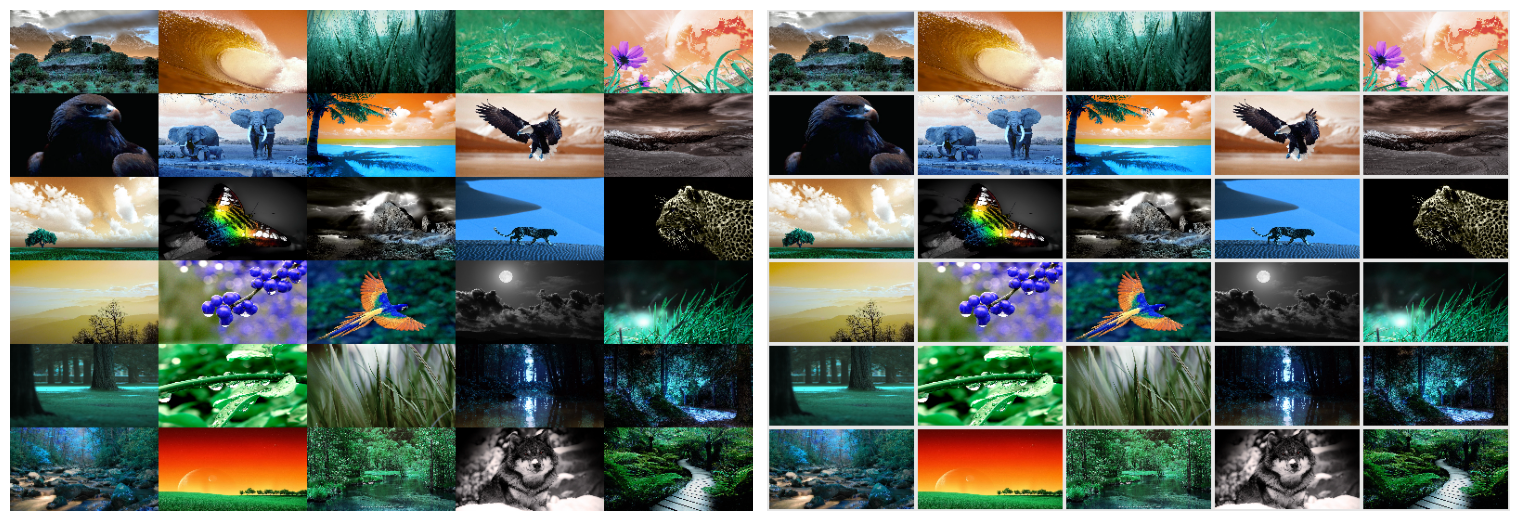

In [69]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
ax1.imshow(tiled[:, :, ::-1])
ax2.imshow(bordered[:, :, ::-1])
ax1.axis("off")
ax2.axis("off")
fig.subplots_adjust(0, 0, 1, 1, 0.02, 0)
plt.show()

## 多项式函数

多项式是变量的整数次幂与系数之积的和，用下面的式子表示。

$$f(x) = a_n x^n + a_{n-1} x^{n-1} + \cdots + a_2 x^2 + a_1 x + a_0$$

多项式只用加法和乘法就能算出来，所以常被用来近似其他函数，单片机里计算正弦、余弦时也会用到。NumPy 用一维数组表示多项式的系数，例如 $f(x) = x^3 - 2 x + 1$ 对应下面的数组，其中 `a[0]` 是最高次项的系数、`a[-1]` 是常数项，要注意 $x^2$ 的系数是 0。

In [70]:
coeffs = np.array([1.0, 0, -2, 1])   # x^3 + 0*x^2 - 2*x + 1

用 `poly1d()` 可以把系数转换成 `poly1d`(一元多项式)对象，这个对象能像函数一样调用，返回多项式的值。

In [71]:
poly = np.poly1d(coeffs)
print(type(poly))
poly(np.linspace(0, 1, 5))

<class 'numpy.poly1d'>


array([ 1.      ,  0.515625,  0.125   , -0.078125,  0.      ])

`poly1d` 对象之间做四则运算，就是多项式之间的计算。

In [72]:
poly + [-2, 1]   # 与 poly + np.poly1d([-2, 1]) 相同

poly1d([ 1.,  0., -4.,  2.])

In [73]:
poly * poly   # 两个 3 次式相乘得到 6 次式

poly1d([ 1.,  0., -4.,  2.,  4., -4.,  1.])

In [74]:
poly / [1, 1]   # 除法返回商和余数两个多项式

(poly1d([ 1., -1., -1.]), poly1d([2.]))

多项式除法不一定能整除，所以返回商和余数：上面的例子里商是 $x^2 - x - 1$、余数是 2，商与除数的积再加上余数，就回到原来的 `poly`。

In [75]:
poly == np.poly1d([1.0, -1.0, -1.0]) * [1, 1] + 2

np.True_

`deriv()` 与 `integ()` 分别计算微分和积分。

In [76]:
poly.deriv()

poly1d([ 3.,  0., -2.])

In [77]:
poly.integ()

poly1d([ 0.25,  0.  , -1.  ,  1.  ,  0.  ])

In [78]:
poly.integ().deriv() == poly   # 积分再微分就回到原式

np.True_

多项式的根可以用 `roots()` 计算。

In [79]:
roots = np.roots(poly)
roots

array([-1.61803399,  1.        ,  0.61803399])

In [80]:
poly(roots)   # 代入根得到接近 0 的值

array([2.33146835e-15, 4.44089210e-16, 1.11022302e-16])

用 `poly()` 可以从根回到系数。

In [81]:
np.poly(roots)

array([ 1.00000000e+00, -6.66133815e-16, -2.00000000e+00,  1.00000000e+00])

也有不使用 `poly1d`、直接处理系数数组的函数，在 IPython 里可以用补全看函数名。

    >>> np.poly # 按 Tab 键
    np.poly    np.polyadd np.polydiv np.polyint np.polysub
    np.poly1d  np.polyder np.polyfit np.polymul np.polyval

In [82]:
np.polymul([1, 1], [1, 1])

array([1, 2, 1])

`polyfit()` 对给定数据拟合一个多项式，返回让误差平方和最小的系数。下面的程序在 $-\pi/2 \sim \pi/2$ 的区间上，计算与 $\sin(x)$ 最接近的多项式。

In [83]:
np.set_printoptions(suppress=True, precision=4)

x = np.linspace(-np.pi / 2, np.pi / 2, 1000)   # ❶ 把区间分成 1000 个点
y = np.sin(x)                                  # ❷ 目标函数的值

for degree in [3, 5, 7]:
    a = np.polyfit(x, y, degree)               # ❸ 拟合得到系数
    error = np.abs(np.polyval(a, x) - y)        # ❹ 计算误差
    print(f"degree {degree}: {a}")
    print(f"max error of order {degree}: {np.max(error)}")

degree 3: [-0.145  -0.      0.9887  0.    ]
max error of order 3: 0.008946993767073308
degree 5: [ 0.0076 -0.     -0.1658  0.      0.9998 -0.    ]
max error of order 5: 0.0001574086141702402
degree 7: [-0.0002  0.      0.0083 -0.     -0.1667  0.      1.     -0.    ]
max error of order 7: 1.5268255812994624e-06


❶ 先用 `linspace()` 把 $-\pi/2 \sim \pi/2$ 分成 1000 个点，❷ 再算出目标值 $\sin(x)$，❸ 然后把这个数组交给 `polyfit()`，第 3 个参数 `degree` 就是多项式的次数。`polyfit()` 返回的是让这 1000 个点与目标之间误差最小的系数，❹ 最后用 `polyval()` 算出多项式的值，并求它与目标之差的绝对值。

由于 $\sin(x)$ 是奇函数，只用奇次多项式去拟合就够了，从输出可以看到偶次项的系数几乎为 0。下图是不同次数所对应的误差，要注意纵轴是对数刻度。

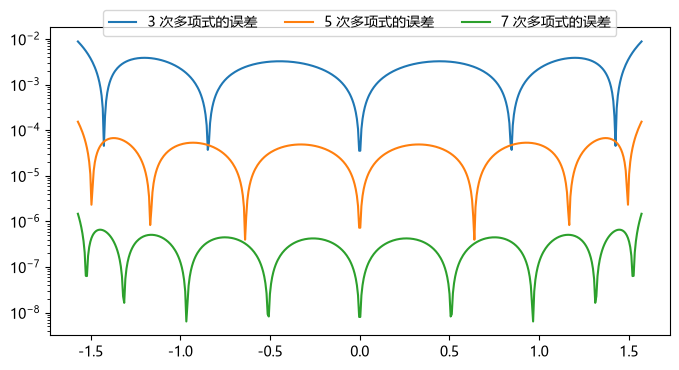

In [84]:
plt.figure(figsize=(8, 4))

x = np.linspace(-np.pi / 2, np.pi / 2, 500)
y = np.sin(x)

for degree in [3, 5, 7]:
    a = np.polyfit(x, y, degree)
    error = np.abs(np.polyval(a, x) - y)
    plt.semilogy(x, error, label=f"{degree} 次多项式的误差")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, 1.08), ncol=3, fancybox=True)
plt.axis("tight")
plt.show()

### 多项式函数类

`numpy.polynomial` 模块提供了 `Polynomial`、`Chebyshev`、`Legendre` 等表示多项式的类。与 `numpy.poly1d` 不同的是，这些类的系数按次数从低到高排列。下面的例子用 `Polynomial` 表示 $x^3 - 2 x + 1$，并计算 $x=2$ 时的值。

In [85]:
from numpy.polynomial import Chebyshev, Polynomial

p = Polynomial([1, -2, 0, 1])   # 1 - 2x + 0x^2 + x^3
print(p)
print(p(2.0))

1.0 - 2.0 x + 0.0 x**2 + 1.0 x**3
5.0


`Polynomial` 有很多处理多项式的方法，例如 `deriv()` 返回导函数。

In [86]:
print(p.deriv())

-2.0 + 0.0 x + 3.0 x**2


切比雪夫多项式是正交多项式序列 $T_i(x)$，n 次多项式可以表示成切比雪夫多项式的加权和，在 NumPy 里就用 `Chebyshev` 类表示 $p(x) = \sum_{i=0}^n c_i T_i(x)$。

$T_i(x)$ 可以用 `Chebyshev.basis(i)` 取得，下图是 0 次到 4 次的切比雪夫多项式。用 `convert()` 可以把它们转换成另一种多项式，转换的目标由 `kind` 指定；下面的例子把 $T_4(x)$ 转换成 `Polynomial`，从结果可以看出 $T_4(x) = 1 - 8 x^2 + 8 x^4$。

In [87]:
print(Chebyshev.basis(4).convert(kind=Polynomial))

1.0 + 0.0 x - 8.0 x**2 + 0.0 x**3 + 8.0 x**4


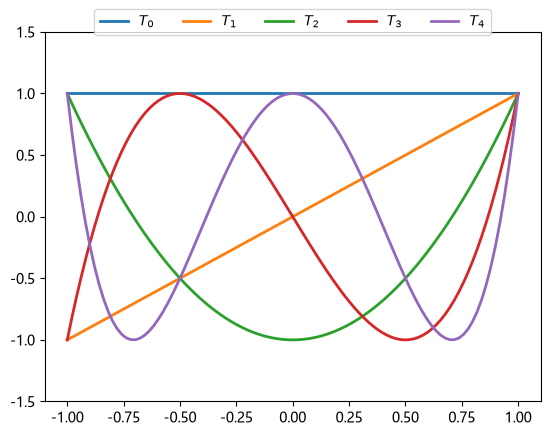

In [88]:
x = np.linspace(-1, 1, 100)
for i in range(5):
    plt.plot(x, Chebyshev.basis(i)(x), lw=2, label=f"$T_{i}$")
plt.ylim(-1.5, 1.5)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, 1.08), ncol=5, fancybox=True)
plt.show()

切比雪夫多项式的根称为切比雪夫节点，可以用来做多项式的插值。拿切比雪夫节点当插值点，可以抑制龙格现象，让连续函数的逼近更均匀。下面的例子用 $f(x) = \frac{1}{1+25x^2}$ 的插值来确认切比雪夫节点与龙格现象。

❶ 先在 $[-1, 1]$ 上等间隔取 n 个点，❷ 再取 n 次切比雪夫多项式的根作为插值点，❸ 然后用这两种插值点分别对 $f(x)$ 做插值，也就是求出通过所有点的多项式。下图左边是等间隔的点，右边是切比雪夫节点：左边在两端出现很大的振荡，这就是龙格现象，n 越大振荡越强；右边则振荡很小，而且 n 越大反而越小。

:::{admonition} 插值与拟合
:class: note
多项式插值要求找出通过所有插值点的多项式。n 次多项式有 n+1 个系数，所以通过 n+1 个点的多项式系数可以通过解联立方程得到。`fit()` 计算的是与目标点相合的多项式系数，而用 n 次多项式去拟合 n+1 个点时，多项式恰好通过所有点，结果与插值相同。
:::

In [89]:
def f(x):
    return 1.0 / (1 + 25 * x**2)


n = 11
nodes_uniform = np.linspace(-1, 1, n)          # ❶ 等间隔的点
nodes_cheb = Chebyshev.basis(n).roots().real        # ❷ 切比雪夫节点
xd = np.linspace(-1, 1, 200)

interp_uniform = Chebyshev.fit(nodes_uniform, f(nodes_uniform), n - 1, domain=[-1, 1])   # ❸
interp_cheb = Chebyshev.fit(nodes_cheb, f(nodes_cheb), n - 1, domain=[-1, 1])

print("插值多项式的最大误差：", end=" ")
print("等间隔采样点：", abs(interp_uniform(xd) - f(xd)).max(), end=" ")
print("切比雪夫节点：", abs(interp_cheb(xd) - f(xd)).max())

插值多项式的最大误差： 等间隔采样点： 1.915569330290325 切比雪夫节点： 0.10914982501448134


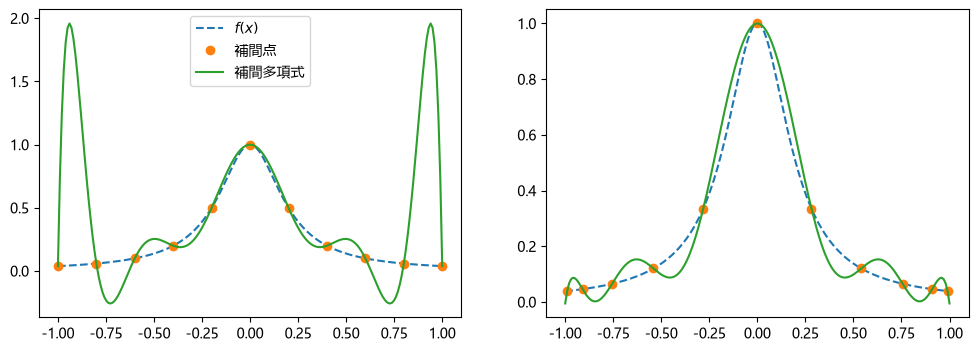

In [90]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(xd, f(xd), "--", label="$f(x)$")
ax1.plot(nodes_uniform, f(nodes_uniform), "o", label="補間点")
ax1.plot(xd, interp_uniform(xd), label="補間多項式")
ax1.legend(loc="upper center")

ax2.plot(xd, f(xd), "--")
ax2.plot(nodes_cheb, f(nodes_cheb), "o")
ax2.plot(xd, interp_cheb(xd))
plt.show()

用多项式逼近函数时，改用切比雪夫多项式误差会小得多。下面的例子用 100 个切比雪夫节点对 $g(x)$ 做插值，比较 `Polynomial` 与 `Chebyshev` 的结果：`Polynomial.fit()` 会给出 `RankWarning: The fit may be poorly conditioned` 的警告，而且得到的多项式并没有通过所有点。

In [91]:
def g(x):
    x = (x - 1) * 5
    return np.sin(x**2) + np.sin(x) ** 2


n = 100
nodes = Chebyshev.basis(n).roots().real
xd = np.linspace(-1, 1, 1000)

poly_g = Polynomial.fit(nodes, g(nodes), n - 1, domain=[-1, 1])
cheb_g = Chebyshev.fit(nodes, g(nodes), n - 1, domain=[-1, 1])

print("Max Polynomial Error:", abs(g(xd) - poly_g(xd)).max())
print("Max Chebyshev Error:", abs(g(xd) - cheb_g(xd)).max())

Max Polynomial Error: 1.1949288697806564
Max Chebyshev Error: 6.475756375579067e-09


C:\pixi_env\.pixi\envs\default\Lib\site-packages\numpy\polynomial\polynomial.py:1499: RankWarning: The fit may be poorly conditioned
  return pu._fit(polyvander, x, y, deg, rcond, full, w)


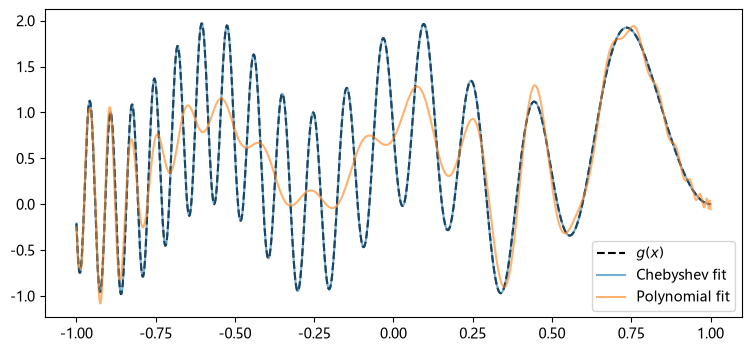

In [92]:
plt.figure(figsize=(9, 4))
plt.plot(xd, g(xd), "k--", label="$g(x)$")
plt.plot(xd, cheb_g(xd), alpha=0.6, label="Chebyshev fit")
plt.plot(xd, poly_g(xd), alpha=0.6, label="Polynomial fit")
plt.legend(loc="best")
plt.show()

用 `trim()` 可以降低多项式的次数，它会把高次系数中绝对值小于 `tol` 的那些去掉。下面的例子把 `cheb_g` 截短，看误差会增大到什么程度。

In [93]:
cheb_trimmed = cheb_g.trim(tol=0.05)
print("degree:", cheb_trimmed.degree())
print("error:", abs(g(xd) - cheb_trimmed(xd)).max())

degree: 68
error: 0.09120948354583083


用同样的办法，把函数 $h(x)$ 用 19 次切比雪夫多项式插值。

In [94]:
def h(x):
    x = 5 * x
    return np.exp(-(x**2) / 10)


n = 20
nodes = Chebyshev.basis(n).roots().real
cheb_h = Chebyshev.fit(nodes, h(nodes), n - 1, domain=[-1, 1])

print("Max Chebyshev Error:", abs(h(xd) - cheb_h(xd)).max())

Max Chebyshev Error: 1.665437787679025e-09


多项式的类支持四则运算。下面的例子从 `cheb_g` 里减去 `cheb_h` 得到 `cheb_diff`，再用 `roots()` 求根，其中的实根就是 $g(x)$ 与 $h(x)$ 交点处的 x 坐标。

In [95]:
cheb_diff = cheb_g - cheb_h
roots = cheb_diff.roots()
real_roots = roots[roots.imag == 0].real
print(np.allclose(cheb_diff(real_roots), 0))

True


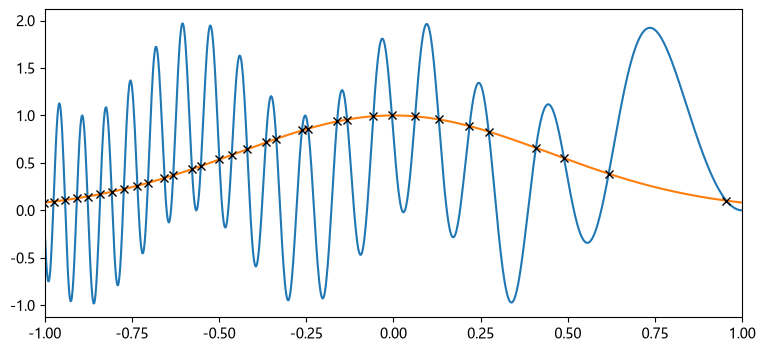

In [96]:
plt.figure(figsize=(9, 4))
plt.plot(xd, g(xd))
plt.plot(xd, h(xd))
plt.plot(real_roots, h(real_roots), "kx", markeredgewidth=1)
plt.xlim(-1, 1)
plt.show()

切比雪夫多项式只在区间 $[-1, 1]$ 上正交，因此也只有在这个区间上才能正确地插值；要在别的区间上插值，就得对自变量做伸缩和平移。`domain` 用来指定插值点所在的区间，下面的例子在 $[-10, 0]$ 上对 $g_2(x)$ 做插值：❶ 用 `basis()` 生成 $T_n(x)$ 时指定 `domain`，就得到该区间上的切比雪夫节点；❷ 给 `fit()` 指定同样的 `domain`；❸ 最后显示所得多项式在 $[-10, 0]$ 上的最大误差。

In [97]:
def g2(x):
    return np.sin(x**2) + np.sin(x) ** 2


n = 100
nodes = Chebyshev.basis(n, domain=[-10, 0]).roots().real          # ❶
xd = np.linspace(-10, 0, 1000)

cheb_g2 = Chebyshev.fit(nodes, g2(nodes), n - 1, domain=[-10, 0])   # ❷

print("Max Chebyshev Error:", abs(g2(xd) - cheb_g2(xd)).max())      # ❸

Max Chebyshev Error: 6.475726621602007e-09


## 各种乘积运算

| 函数名 | 功能 | 函数名 | 功能 |
|:--|:--|:--|:--|
| `dot`  | 矩阵乘积 | `inner`  | 内积 |
| `outer`  | 外积 | `tensordot` | 张量积 |

矩阵的乘积用 `dot()` 计算：二维数组时是矩阵乘积，一维数组时是内积。想把一维数组当作行向量或列向量，先把它转换成二维数组。

In [98]:
a = np.array([1, 2, 3])
%C a[:, None]; a[None, :]

a[:, None]   a[None, :]
----------  -----------
[[1],       [[1, 2, 3]]
 [2],                  
 [3]]                  


`dot()` 作用在多维数组上时，可以用下面的式子表示，结果的每个元素是 `a` 的最后一轴与 `b` 的倒数第二轴相乘再求和。

    dot(a, b)[i,j,k,m] = sum(a[i,j,:] * b[k,:,m])

用两个三维数组相乘来确认：两个数组最后的两个轴正好构成矩阵乘积的形状。

In [99]:
a = np.arange(12).reshape(2, 3, 2)
b = np.arange(12, 24).reshape(2, 2, 3)
c = np.dot(a, b)
c.shape

(2, 3, 2, 3)

`c` 就是把 `a` 与 `b` 的子矩阵两两相乘之后排起来的结果。把 `a` 看成 2 个形状为 `(3, 2)` 的矩阵、`b` 看成 2 个形状为 `(2, 3)` 的矩阵，那么 `c[i, :, j, :]` 就是 `a` 中第 i 个矩阵与 `b` 中第 j 个矩阵的乘积。

In [100]:
for i, j in np.ndindex(2, 2):
    assert np.all(c[i, :, j, :] == np.dot(a[i], b[j]))

对一维数组来说，`inner()` 与 `dot()` 相同，返回同一位置元素乘积之和；对多维数组，结果的每个元素是 `a` 与 `b` 在最后一轴上的内积，因此两个数组最后一轴的长度必须相同。

    inner(a, b)[i,j,k,m] = sum(a[i,j,:]*b[k,m,:])

下面是 `inner()` 的例子。

In [101]:
a = np.arange(12).reshape(2, 3, 2)
b = np.arange(12, 24).reshape(2, 3, 2)
c = np.inner(a, b)
c.shape

(2, 3, 2, 3)

In [102]:
for i, j, k, l in np.ndindex(2, 3, 2, 3):
    assert c[i, j, k, l] == np.inner(a[i, j], b[k, l])

`outer()` 只处理一维数组，传多维数组时会先展平再计算，结果相当于列向量与行向量之积。

In [103]:
a = np.array([1, 2, 3])
b = np.array([4, 5, 6, 7])
%C np.outer(a, b); np.dot(a[:, None], b[None, :])

  np.outer(a, b)    np.dot(a[:, None], b[None, :])
------------------  ------------------------------
[[ 4,  5,  6,  7],  [[ 4,  5,  6,  7],            
 [ 8, 10, 12, 14],   [ 8, 10, 12, 14],            
 [12, 15, 18, 21]]   [12, 15, 18, 21]]            


`tensordot()` 计算两个多维数组 `a` 与 `b` 在指定轴上乘积之和，是所有乘积运算里最一般的函数。先看两个矩阵相乘的情形：❶ `axes` 有 2 个元素，第 1 个是 `a` 的轴、第 2 个是 `b` 的轴，函数求这两个轴上乘积之和；❷ `axes` 也可以给整数，这时求的是 `a` 后面 `axes` 个轴与 `b` 前面 `axes` 个轴上乘积之和，其余轴原样保留。

In [104]:
a = np.random.rand(3, 4)
b = np.random.rand(4, 5)

c1 = np.tensordot(a, b, axes=[[1], [0]])   # ❶ a 的第 1 轴与 b 的第 0 轴
c2 = np.tensordot(a, b, axes=1)            # ❷ 同样的含义
c3 = np.dot(a, b)
assert np.allclose(c1, c3)
assert np.allclose(c2, c3)

多维数组的 `dot()` 与 `tensordot(a, b, axes=[[-1], [-2]])` 相同，求的都是 `a` 的最后一轴与 `b` 的倒数第二轴上乘积之和。

In [105]:
a = np.arange(12).reshape(2, 3, 2)
b = np.arange(12, 24).reshape(2, 2, 3)
c1 = np.tensordot(a, b, axes=[[-1], [-2]])
c2 = np.dot(a, b)
assert np.all(c1 == c2)

下面的例子求 `a` 的第 1、第 2 轴与 `b` 的第 1、第 0 轴上乘积之和。由于 `b` 的轴顺序是反的，所以需要转置。

    c[i, j, k, l] = np.sum(a[i, :, :, j] * b[:, :, k, l].T)

In [106]:
a = np.random.rand(4, 5, 6, 7)
b = np.random.rand(6, 5, 2, 3)
c = np.tensordot(a, b, axes=[[1, 2], [1, 0]])

for i, j, k, l in np.ndindex(4, 7, 2, 3):
    assert np.allclose(c[i, j, k, l], np.sum(a[i, :, :, j] * b[:, :, k, l].T))

c.shape

(4, 7, 2, 3)

## 广义 ufunc 函数

NumPy 里还有广义 ufunc(generalized ufunc，下面简称 gufunc)。ufunc 把一个数值的计算推广到整个数组，而 gufunc 把一个矩阵的计算推广到整个数组，例如 `numpy.linalg.inv()` 就是求逆矩阵的 gufunc。文档里把它的输入输出形状写成下面这样。

```
ainv = inv(a)
a : (..., M, M)
ainv : (..., M, M)
```

输入 `a` 的形状里的 `...` 表示 0 个或任意多个轴：这部分为空时就是求单个矩阵的逆，而 gufunc 会沿这些轴做广播。最后两个轴的长度 M 就是方阵的大小。

:::{tip}
`numpy.linalg` 里的函数大多是 gufunc。SciPy 也有 `linalg`，但那边是普通函数，一次只算一个矩阵。线性代数的函数会在下一章详细说明。
:::

输出的 `ainv` 里，由于逆矩阵与原矩阵形状相同，最后两个轴的长度也是 `(M, M)`；`...` 这部分是广播之后的形状，逆矩阵是一个矩阵一个矩阵地算，所以与 `a` 的 `...` 相同。

下面的例子里 `a` 的形状是 `(10, 20, 3, 3)`，其中 `(10, 20)` 对应 `...`、3 对应 M。`inv()` 会做广播，求出 $10 \times 20$ 个 `(3, 3)` 矩阵的逆，结果 `ainv` 的形状与 `a` 相同，还是 `(10, 20, 3, 3)`。

In [107]:
a = np.random.rand(10, 20, 3, 3)
ainv = np.linalg.inv(a)
ainv.shape

(10, 20, 3, 3)

把第 i 行第 j 列的矩阵与它的逆相乘，得到的就是三阶单位矩阵。

In [108]:
i, j = 3, 4
np.allclose(np.dot(a[i, j], ainv[i, j]), np.eye(3))

True

`numpy.linalg.det()` 是计算行列式的 gufunc，输入输出的形状如下。

```
adet = det(a)
a : (..., M, M)
adet : (...)
```

由于行列式把 $M \times M$ 的矩阵变成一个数，输出 `adet` 的形状里只剩下 `...`。

In [109]:
adet = np.linalg.det(a)
adet.shape

(10, 20)

接下来看一个把很多条二次函数拟合到数据上的例子，用 gufunc 来加快计算。先用随机数生成 `x` 和 `y`，两者的形状都是 `(n, 10)`。每一行的 `x[i]` 与 `y[i]` 构成一组数据，满足 $y = \beta_2 + \beta_1 x + \beta_0 x^2$ 的关系，现在要逐组求出系数 $\beta$。

In [110]:
n = 10000
np.random.seed(0)
beta = np.random.rand(n, 3)
x = np.random.rand(n, 10)
y = beta[:, 2, None] + x * beta[:, 1, None] + x**2 * beta[:, 0, None]

用 `numpy.polyfit()` 就能轻松做到，下面用第 42 组数据比较原来的系数与拟合出的系数。

In [111]:
print(beta[42])
print(np.polyfit(x[42], y[42], 2))

[0.0192 0.3016 0.6602]
[0.0192 0.3016 0.6602]


调用 n 次 `numpy.polyfit()` 也能得到答案，只是稍慢一些。

In [112]:
%time beta_loop = np.vstack([np.polyfit(x[i], y[i], 2) for i in range(n)])

CPU times: total: 781 ms
Wall time: 810 ms


In [113]:
np.allclose(beta, beta_loop)

True

`numpy.polyfit()` 内部调用的是最小二乘法的 `numpy.linalg.lstsq()`，所以直接调用 `lstsq()` 也能算出系数。

In [114]:
xx = np.column_stack(([x[42] ** 2, x[42], np.ones_like(x[42])]))
print(np.linalg.lstsq(xx, y[42], rcond=-1)[0])

[0.0192 0.3016 0.6602]


不过 `numpy.linalg.lstsq()` 并不是 gufunc，没法把所有组的系数一次算完；而解线性方程的 `numpy.linalg.solve()` 是 gufunc。最小二乘法的公式如下。

$$\mathbf{\hat{\beta}} =( \mathbf{X}^{T} \mathbf{X})^{-1} \mathbf{X}^{T}\mathbf{y}$$

只要先求出 $\mathbf{X}^{T} \mathbf{X}$ 和 $\mathbf{X}^{T} \mathbf{y}$，就能用 `solve()` 算出 $\mathbf{\hat{\beta}}$。矩阵乘积同样需要 gufunc，而 `dot()` 不遵循广播规则，所以这里用矩阵乘积的 gufunc `matmul()`。下面的程序用 `matmul()` 和 `solve()` 把拟合一次算完。

In [115]:
%%time
X = np.dstack([x**2, x, np.ones_like(x)])
Xt = X.swapaxes(-1, -2)

A = np.matmul(Xt, X)
b = np.matmul(Xt, y[..., None])

beta_fast = np.linalg.solve(A, b).squeeze()

print(np.allclose(beta_fast, beta_loop))

True
CPU times: total: 31.2 ms
Wall time: 35.9 ms


`X` 的形状是 `(10000, 10, 3)`，`Xt` 的形状是 `(10000, 3, 10)`，而 `matmul()` 的输入输出形状如下。

```
c = matmul(a, b)
a : (..., M, N)
b : (..., N, K)
c : (..., M, K)
```

`Xt` 与 `X` 逐组相乘，得到 `A` 的形状是 `(10000, 3, 3)`。为了计算 $\mathbf{X}^{T}\mathbf{y}$，用 `y[..., None]` 把 `y` 变成形状 `(10000, 10, 1)`，于是 `matmul(Xt, y[..., None])` 的结果是 `(10000, 3, 1)`。

`solve()` 的 `b` 接受两种形状，这里用到的是下面这种。

```
x = solve(a, b)
a : (..., M, M)
b : (..., M, K)
x : (..., M, K)
```

返回值的形状是 `(10000, 3, 1)`，用 `squeeze()` 去掉长度为 1 的轴就变成 `(10000, 3)`。

到这里为止都是最简单的广播情形，而 gufunc 遵循与 ufunc 相同的广播规则：把形状 `(a, m, n)` 与 `(b, 1, n, k)` 的数组交给 `matmul()` 相乘，结果会是 `(b, a, m, k)`。下面用例子确认。

二维平面上的旋转矩阵是下面这个式子。

$$ M(\theta) = \begin{bmatrix}      \cos{\theta} & -\sin{\theta} \\     \sin{\theta} & \cos{\theta}    \end{bmatrix} $$

它把点绕原点旋转 $\theta$。若形状为 `(N, 2)` 的矩阵 $P$ 表示平面上 N 个点的坐标，那么 $P \cdot M(\theta)$ 就是旋转之后的坐标。下面的程序把 3 条曲线上的点分别按 4 个角度旋转，得到 12 条曲线。

传给 `matmul()` 的两个数组形状分别是 `(3, 100, 2)` 和 `(4, 1, 2, 2)`：广播的轴形状是 `(3,)` 与 `(4, 1)`，做乘积的轴形状是 `(100, 2)` 与 `(2, 2)`。广播之后变成 `(4, 3)`，乘积的轴变成 `(100, 2)`，所以结果 `rpoints` 的形状是 `(4, 3, 100, 2)`。

In [116]:
M = np.array(
    [
        [[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]]
        for t in np.linspace(0, np.pi, 4, endpoint=False)
    ]
)

x = np.linspace(-1, 1, 100)
points = np.array((np.c_[x, x], np.c_[x, x**3], np.c_[x**3, x]))
rpoints = np.matmul(points, M[:, None, ...])

print(points.shape, M.shape, rpoints.shape)

(3, 100, 2) (4, 2, 2) (4, 3, 100, 2)


把 12 条曲线画出来就是下面这张图。

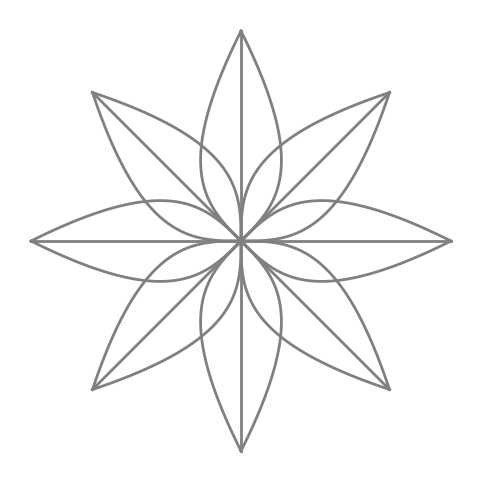

In [117]:
plt.figure(figsize=(6, 6))
for t in rpoints.reshape(-1, 100, 2):
    plt.plot(t[:, 0], t[:, 1], color="gray", lw=2)
ax = plt.gca()
ax.set_aspect("equal")
ax.axis("off")
plt.show()

## 小结

* 随机数用 `numpy.random` 里的函数生成，用 `seed()` 可以固定结果。
* `sum()`、`mean()`、`var()` 等函数用 `axis` 选轴、用 `keepdims` 保留维数、用 `dtype` 指定计算的类型。
* 排序用 `sort()` 与 `argsort()`，前 k 个用 `partition()`，插入位置用 `searchsorted()` 求。
* `unique()` 与 `bincount()` 处理值的种类与出现次数，`histogram()` 计算各区间的频数。
* 按条件选值时用 `where()`，区间多时用 `select()`，想省内存时用 `piecewise()`。
* 连接数组用 `concatenate()` 及其简化版，交换轴用 `transpose()` 与 `swapaxes()`。
* 多项式可以用 `poly1d` 或 `numpy.polynomial` 里的类来处理，用 `polyfit()` 拟合到数据上。
* 乘积运算要在 `dot()`、`inner()`、`outer()`、`tensordot()` 之间选合适的那个；需要把大量矩阵一起算时，可以用 gufunc 的 `matmul()` 与 `solve()`。